In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import multi.modules.dplot as dplot
from statannotations.Annotator import Annotator

In [2]:
acc_tt = np.load("multi/acc/comb/acc_tt.npy", allow_pickle=True).item()
models = list(acc_tt.keys())

In [3]:
records_binary,records_four = [], []
for m in models:
    n_subjects, _, n_times = acc_tt[m].shape

    records_binary.append(pd.DataFrame({
        "model": np.repeat(m, n_subjects * n_times),
        "subject": np.repeat(np.arange(n_subjects), n_times),
        "time": np.tile(np.arange(n_times)/10, n_subjects),
        "Accuracy": acc_tt[m][:, 0, :].reshape(-1)   # binary
    }))
    
    records_four.append(pd.DataFrame({
        "model": np.repeat(m, n_subjects * n_times),
        "subject": np.repeat(np.arange(n_subjects), n_times),
        "time": np.tile(np.arange(n_times)/10, n_subjects),
        "Accuracy": acc_tt[m][:, 1, :].reshape(-1)   # four-class
    }))

df_binary_times = pd.concat(records_binary, ignore_index=True)
df_four_times = pd.concat(records_four, ignore_index=True)

In [4]:
# colors
blues = np.array(sns.color_palette("Blues"))
oranges = np.array(sns.color_palette("Oranges"))
paletteb = {
    "xDAWN+LR": "#062A4A",   # 最深
    "EEGConf":  blues[5],   # 最深
    "EEGNet":   blues[3],
    "EEGNeX":   blues[3],
    "LR":       blues[2],
    "AttBaseNet": blues[2],
}
paletteo = {
    "xDAWN+LR": "#993404",   # 最深
    "EEGConf":  oranges[4],   # 最深
    "EEGNet":   oranges[2],
    "EEGNeX":   oranges[2],
    "LR":       oranges[1],
    "AttBaseNet": oranges[1],
}

dashes = {
    "xDAWN+LR": "",          # solid
    "EEGConf":  (3, 1, 1, 1),          # solid
    "EEGNet":   (2, 1),      # dotted-ish
    "EEGNeX":   (5, 2),      # dashed
    "LR":       "",
    "AttBaseNet": (3, 1, 1, 1),
}

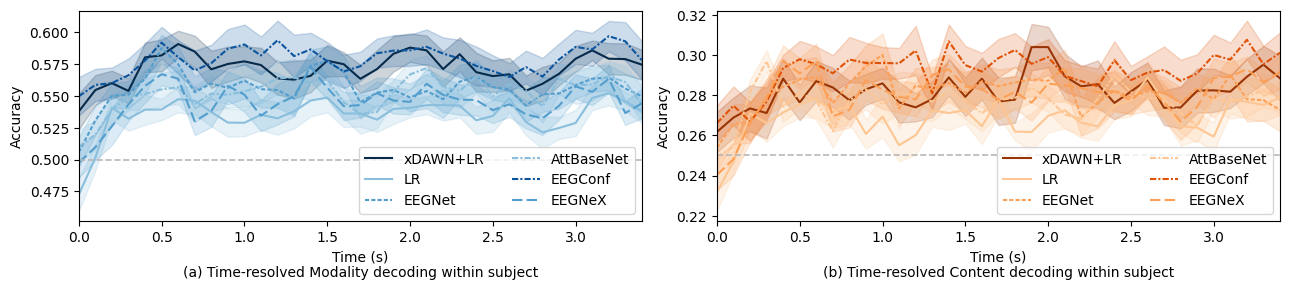

In [5]:
fig = plt.figure(figsize = (13,3))
# ---------- times ----------
ax = plt.subplot2grid((1, 2), (0, 0))
sns.lineplot(data=df_binary_times,x="time",y="Accuracy",hue="model",errorbar="se",ax=ax,style="model",palette=paletteb,dashes=dashes)
ax.set_xlabel("Time (s)\n(a) Time-resolved Modality decoding within subject")
ax.legend(loc="lower right", ncol=2)
ax.set_xlim(0, 3.4)
ax.axhline(0.5, color="#B8B8B8", linestyle='--', linewidth=1.2)
for line in ax.lines:
    label = line.get_label()
    if label in ["xDAWN+LR", "EEGConf"]:
        line.set_linewidth(2.5)

ax = plt.subplot2grid((1, 2), (0, 1))
sns.lineplot(data=df_four_times,x="time",y="Accuracy",hue="model",errorbar="se",ax=ax,style="model",palette=paletteo,dashes=dashes)
ax.set_xlabel("Time (s)\n(b) Time-resolved Content decoding within subject")
ax.legend(loc="lower right", ncol=2)
ax.set_xlim(0, 3.4)
ax.axhline(0.25, color="#B8B8B8", linestyle='--', linewidth=1.2)
for line in ax.lines:
    label = line.get_label()
    if label in ["xDAWN+LR", "EEGConf"]:
        line.set_linewidth(2.5)

plt.savefig("multi/fig/tt.pdf", bbox_inches="tight")
plt.tight_layout()
plt.show()